# Stimulus panels with empirical chord endpoints → `empirical_stimuli_*.pdf`

The two **2-object stimulus panels** from the Stimuli column of
[`../figure_2/psth.ipynb`](../figure_2/psth.ipynb) — the 90°-apart row and the
180°-apart row — for each of that figure's four neurons, with **one change**: each chord's
endpoints are the **circular means of the objects in the trials that chord averaged**, rather
than the prototype positions.

Everything else about the conditions is figure 2's: the same four chords per panel, the same
firing rates, the same shared colour scale, drawn by `psth_lib.draw_2obj_prototypes` itself.
The panels use plain `coolwarm` and that function's default ring radius rather than figure 2's
lifted colormap and radius 0.4, so compare chord *positions* with figure 2, not colours.

**Why there is a deviation at all.** Figure 2 averages each condition over every trial whose
two objects were both within `SIMILARITY_WINDOW_DEG` = 15° of their prototype slot, so a
prototype is a label for a small cloud of real stimuli rather than a stimulus that was ever
shown on its own.

Two details decide whether the means are right, both handled in `empirical_lib`:

* **the pair is unordered** — a trial joins a bin under whichever object-to-slot assignment
  fits better, so each trial's objects are put back into the slots they were *matched through*
  before averaging;
* **angles are circular**, so the mean is the angle of the summed unit vectors.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# `figure_2` first: `psth_lib` does `from common import ...` and needs FIGURE 2's `common`,
# which is why this directory deliberately has none of its own (see README.md).
# The repository root (where paths.py lives), found from this notebook's folder.
_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'paths.py').exists())
sys.path.insert(0, str(_root))
import paths
sys.path.insert(0, str(paths.FIGURES / 'figure_2'))
import common

common.set_style()
import empirical_lib as el

# ── These must match ../figure_2/psth.ipynb ──────────────────────────────────
# The panels are that figure's, redrawn; if a knob here differs they are not the same panels
# and the comparison the supplement makes is not about figure 2.
# (subject, session, unit, prototype orientation in degrees, share the 2-object colour scale)
UNITS = [
    ('Perle', '2022-06-11', 188, 48, True),
    ('Perle', '2022-06-11', 126, 11, False),
    ('Perle', '2022-06-11', 143, 88, False),
    ('Perle', '2022-06-10', 47, 0, False),
]
SIMILARITY_WINDOW_DEG = 15.0  # both objects must be within this of their prototype slot
SMOOTH_HALF_WIN_MS = 250.0    # temporal smoothing half-window of the firing rates
N_PROTO = 4                   # chords per panel

OUTPUT = 'empirical_stimuli_{subject}_{session}_{unit_id}.pdf'

# ── This figure's own layout ─────────────────────────────────────────────────
PANEL_IN = 1.25          # side of one ring panel, in inches
MARGIN = (0.30, 0.45)    # inches added for the titles and the colour bar label

## The panels, one figure per neuron

Perle 2022-06-11: 932 2-obj + 192 1-obj trials | unit 188 @ s0/good (1170 trials with spikes) | prototypes at 48°
saved empirical_stimuli_Perle_2022-06-11_188.pdf


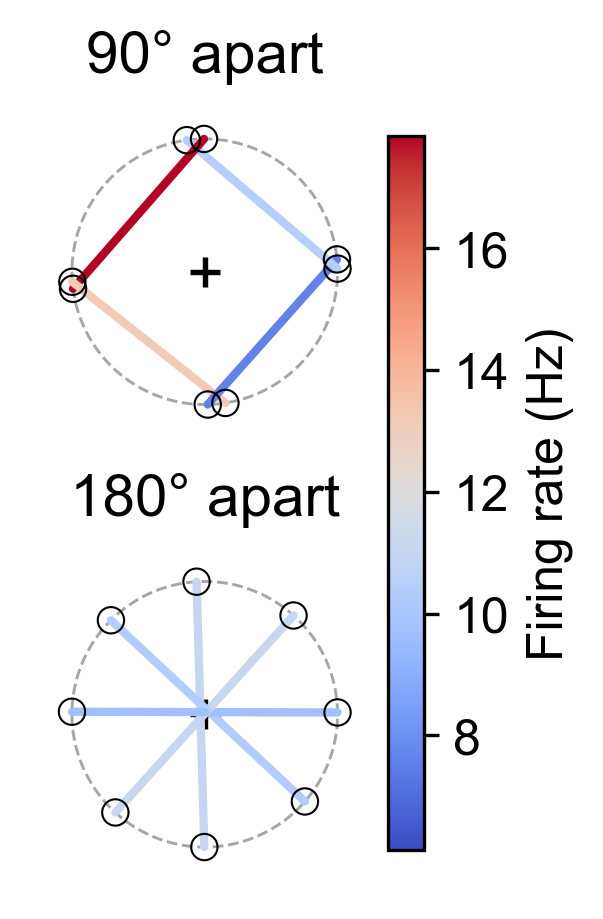

Perle 2022-06-11: 932 2-obj + 192 1-obj trials | unit 126 @ s0/good (1170 trials with spikes) | prototypes at 11°
saved empirical_stimuli_Perle_2022-06-11_126.pdf


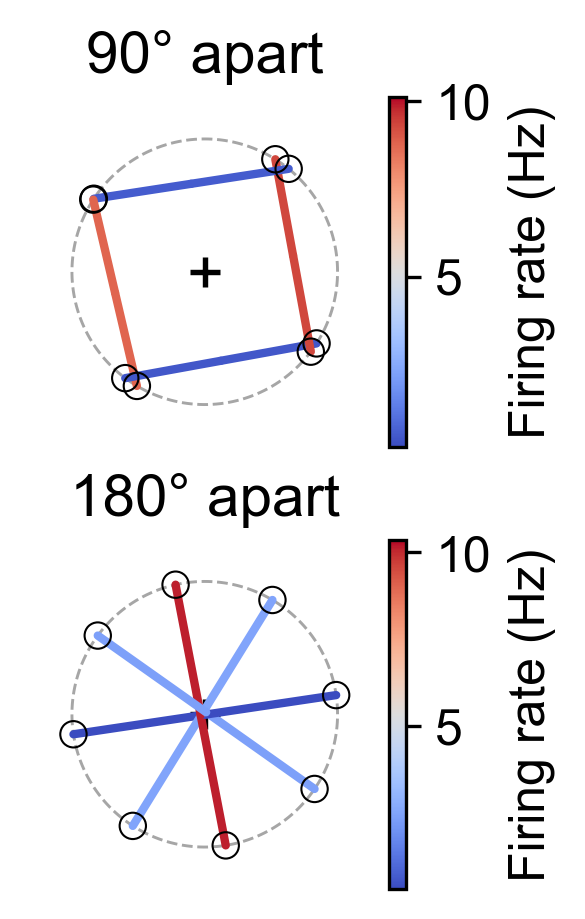

Perle 2022-06-11: 932 2-obj + 192 1-obj trials | unit 143 @ s0/good (1170 trials with spikes) | prototypes at 88°
saved empirical_stimuli_Perle_2022-06-11_143.pdf


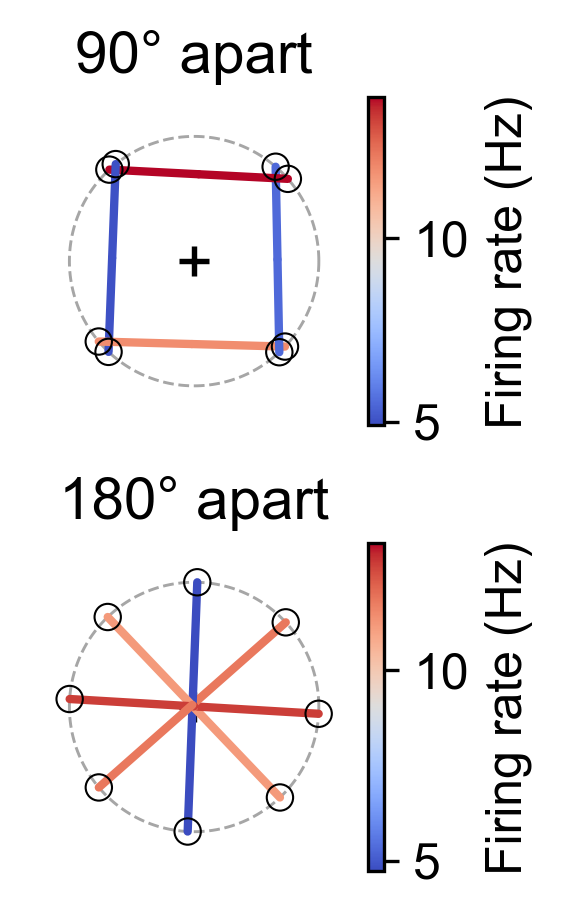

Perle 2022-06-10: 962 2-obj + 198 1-obj trials | unit 47 @ vprobe0/mua (1206 trials with spikes) | prototypes at 0°
saved empirical_stimuli_Perle_2022-06-10_47.pdf


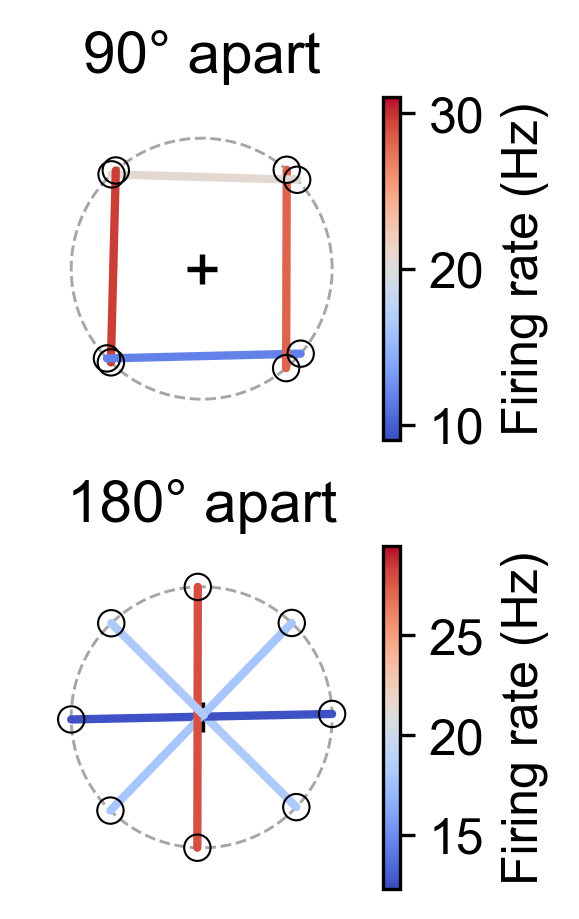

In [2]:
tables = []
for subject, session, unit_id, orientation, share in UNITS:
    fig, _, t = el.empirical_stimulus_figure(
        subject, session, unit_id, orientation_deg=orientation,
        similarity_window_deg=SIMILARITY_WINDOW_DEG, n_proto=N_PROTO,
        share_2obj_color_scale=share,
        smooth_half_win_ms=SMOOTH_HALF_WIN_MS,
        panel_in=PANEL_IN, margin=MARGIN)
    t.insert(0, 'unit', f'{subject} {session} u{unit_id}')
    tables.append(t)
    common.save(fig, OUTPUT.format(subject=subject, session=session, unit_id=unit_id))
    plt.show()

table = pd.concat(tables, ignore_index=True)

## How far did the endpoints move?

The supplement exists to support a sentence about the size of this deviation, so here it is as
a number. `dev_deg` is the **worse of a chord's two endpoints**, which is the rule that
admitted the trial in the first place — `psth_lib._dist_2obj` takes the worse of the two
per-object distances.

In [3]:
d = table['dev_deg'].to_numpy(float)
print(f'{len(d)} chords over {table["unit"].nunique()} neurons, '
      f'window = {SIMILARITY_WINDOW_DEG:g}°')
print(f'  endpoint deviation from the prototype:')
print(f'    median {np.median(d):.2f}°   mean {d.mean():.2f}°   max {d.max():.2f}°')
print(f'    {100 * np.mean(d <= 5):.0f}% within 5°, {100 * np.mean(d <= 10):.0f}% within 10°')
print(f'  trials per chord: median {int(table["n"].median())}, '
      f'range {int(table["n"].min())}–{int(table["n"].max())}')
print()
print(table.groupby('row')[['n', 'dev_deg']].agg(['median', 'max']).round(2).to_string())

32 chords over 4 neurons, window = 15°
  endpoint deviation from the prototype:
    median 2.91°   mean 2.99°   max 6.18°
    91% within 5°, 100% within 10°
  trials per chord: median 21, range 13–31

                n     dev_deg      
           median max  median   max
row                                
180° apart   24.0  31    1.90  4.09
90° apart    18.0  29    3.95  6.18
